In [1]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.dates as mdates
import os

         Date  Water Volume      diff1
85 1998-02-01    30600608.0 -3175356.0
86 1998-03-01    33667807.0  3067199.0
87 1998-04-01    31762202.0 -1905605.0
88 1998-05-01    32499828.0   737626.0
89 1998-06-01    30791705.0 -1708123.0


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_21580\1526734232.py:28: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  training = cleaned[training_mask]


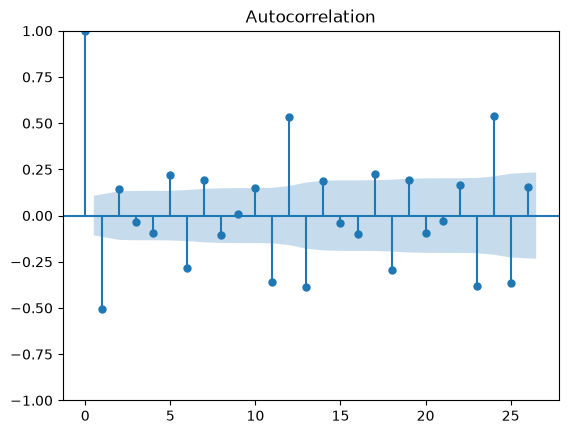

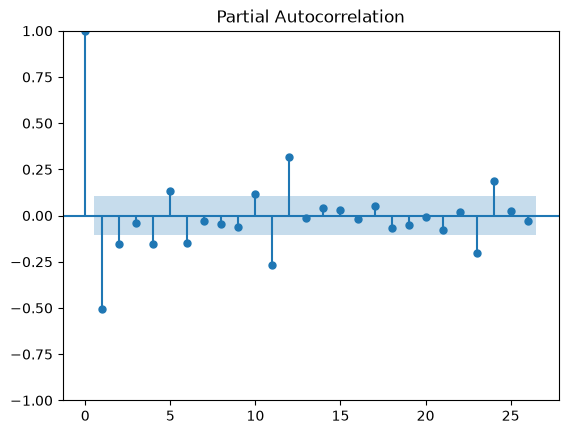

In [6]:

#AUTOCORRELATION FOR 1998 TO 2025
df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])


# change Date to a Period data type
#monthly_water_vols['Date'] = monthly_water_vols['Date'].dt.to_period(freq='M')


# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]

monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)
cleaned = monthly_water_vols.dropna()

training_mask = (cleaned['Date'] >= '1998-01') & (monthly_water_vols['Date'] <= '2025-12')
training = cleaned[training_mask]

training_data_large = np.asarray(training['diff1'])
#Plotting ACF and PACF graphs
plot_acf(training_data_large)
plot_pacf(training_data_large)
plt.show()

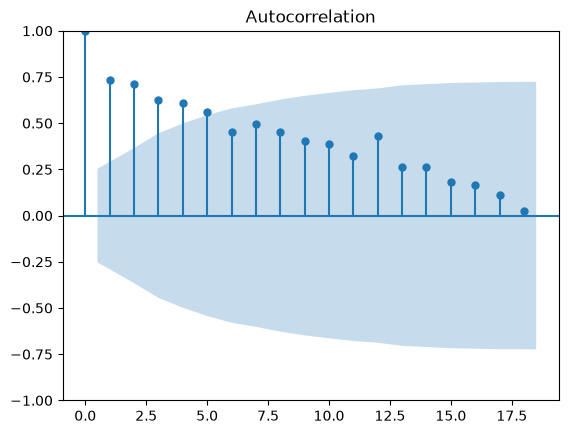

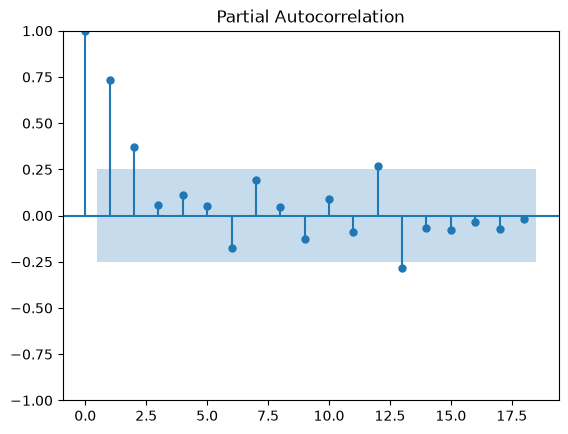

In [3]:
#aUTOCORRELATION FOR AFTER COVID
df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")
pd.set_option('display.max_rows', 90)

monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# change Date to a Period data type
#monthly_water_vols['Date'] = monthly_water_vols['Date'].dt.to_period(freq='M')


# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]



#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '2021-01') & (monthly_water_vols['Date'] <= '2026-07')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '2021-01') & (subset['Date'] <= '2025-12')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2026-01') & (subset['Date'] <= '2026-07')
validation = subset[validation_mask]

training_data = np.asarray(training['Water Volume'])

plot_acf(training_data)
plot_pacf(training_data)
plt.show()


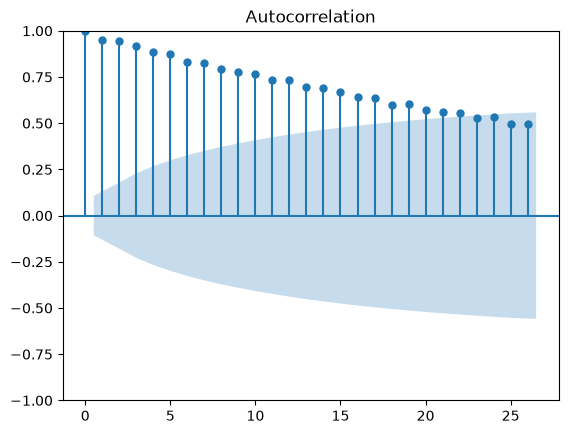

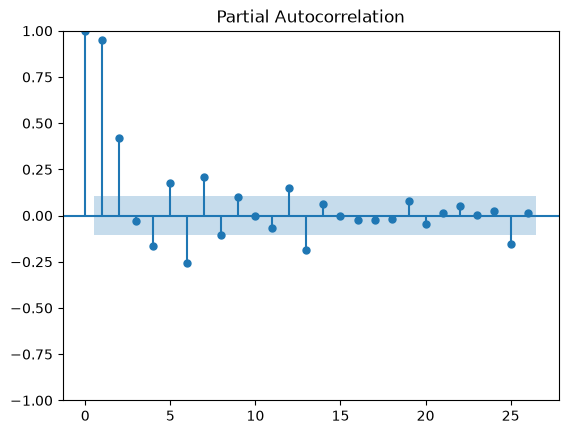

In [4]:
#AUTOCORRELATION FOR ADJUSTED VALUES FROM 1998 TO 2025
#Accessing the adjusted values from SARIMA Project
adjusted_df = pd.read_excel(r"C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\Water Disposal History.xlsx", sheet_name='Sheet2')
adjusted = adjusted_df[['Date', 'Total Water Volume 1']]

mask = (adjusted['Date'] >= '1998-01') & (adjusted['Date'] <= '2025-12')
subset = adjusted[mask]
training_array = np.asarray(subset['Total Water Volume 1'])

plot_acf(training_array)
plot_pacf(training_array)
plt.show()

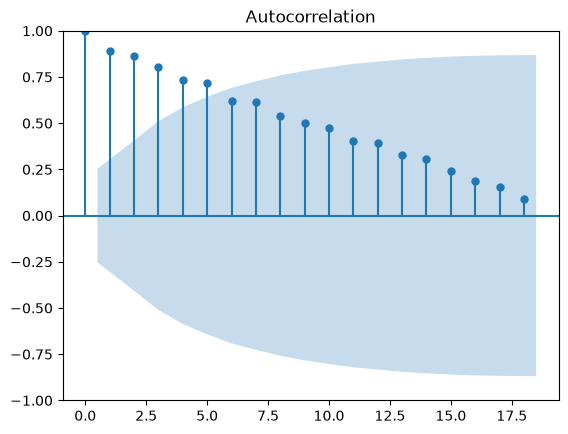

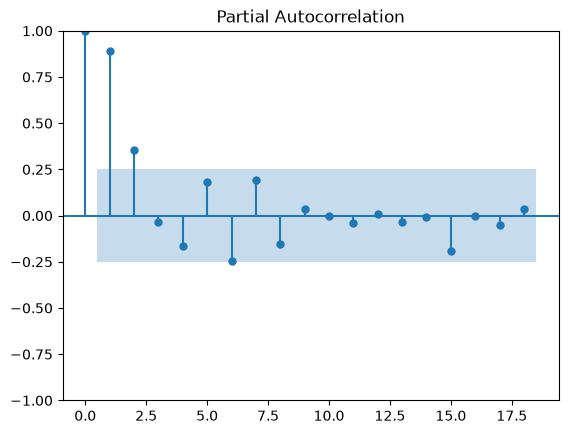

In [5]:
#AUTOCORRELATION FOR ADJUSTED VALUES FROM AFTER COVID
#Accessing the adjusted values from SARIMA Project
adjusted_df = pd.read_excel(r"C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\Water Disposal History.xlsx", sheet_name='Sheet2')
adjusted = adjusted_df[['Date', 'Total Water Volume 1']]

mask = (adjusted['Date'] >= '2021-01') & (adjusted['Date'] <= '2025-12')
subset = adjusted[mask]
training_array = np.asarray(subset['Total Water Volume 1'])

plot_acf(training_array)
plot_pacf(training_array)
plt.show()
